# Participant logs: organization, coverage and modeling readiness

A short audit of `data/rte_participants` and `data/tennet_participants`. These are human user-study logs with Grid2Op-formatted states and selected recommendations, not continuous sensor trajectories. The RTE study transcripts explicitly describe a simulator/fictitious network. Human decisions are real, but physical-grid deployment is not established by these exports.

We count sessions, event cards, recommendations and decisions separately. In particular, `AWARD` is the UI/application label for a selected action payload; it does **not** mean an RL reward. We retain source filenames and session IDs so every extracted row is traceable.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import json
import zipfile
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
GROUPS = {"RTE": ROOT / "data/rte_participants", "TenneT": ROOT / "data/tennet_participants"}
OUT = ROOT / "artifacts/participant_audit"
OUT.mkdir(parents=True, exist_ok=True)

def fingerprint(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()

def timestamp(value):
    return pd.to_datetime(value, utc=True, errors="coerce")

def scalar(obs, field):
    values = obs.get(field, [])
    return values[0] if isinstance(values, list) and values else values if not isinstance(values, list) else np.nan

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / f"{name}.png", dpi=140, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 1. Folder structure and file roles

Both folders are flat. `historic-session-*.json` is the structured source; matching `.html` files are readable reports with embedded grid images, not additional sessions. `survey_session_*.json` contains questionnaire responses. RTE also provides six study-note/transcript DOCX files and a questionnaire template.

Link surveys by `participantData.id == sessionId`, not filename time: clocks/time zones may differ. A shared `userLogin` is not a unique human identifier; ten sessions do not necessarily mean ten people.

In [2]:
inventory_rows, session_sources, survey_sources = [], [], []
for organization, folder in GROUPS.items():
    for path in sorted(folder.iterdir()):
        if not path.is_file():
            continue
        role = ("session" if path.name.startswith("historic") and path.suffix == ".json" else
                "survey" if path.name.startswith("survey") else
                "HTML report" if path.suffix == ".html" else "study document")
        inventory_rows.append(dict(organization=organization, file=path.name, role=role,
                                   suffix=path.suffix, size_kb=path.stat().st_size/1024))
        if role in ["session", "survey"]:
            item = dict(organization=organization, file=path.name, data=json.loads(path.read_text()))
            (session_sources if role == "session" else survey_sources).append(item)
inventory = pd.DataFrame(inventory_rows)
display(pd.crosstab(inventory.organization, inventory.role))
display(inventory[["organization", "file", "role", "size_kb"]])

# Read text structure only; this is not a document-layout review.
# Report document types/coverage without publishing transcript names or full conversations.
document_rows = []
namespace = {"w": "http://schemas.openxmlformats.org/wordprocessingml/2006/main"}
for path in sorted(GROUPS["RTE"].glob("*.docx")):
    with zipfile.ZipFile(path) as archive:
        tree = ET.fromstring(archive.read("word/document.xml"))
        paragraphs = ["".join(p.itertext()) for p in tree.findall(".//w:p", namespace)]
        text = " ".join(paragraphs).lower()
    document_rows.append(dict(file=path.name, paragraphs=len(paragraphs),
        simulator_mentioned=any(word in text for word in ["simulateur", "simulation", "réseau fictif"]),
        questionnaire="questionnaire" in path.name.lower()))
documents = pd.DataFrame(document_rows)
display(documents)

role,HTML report,session,study document,survey
organization,,,,
RTE,4,6,7,5
TenneT,2,4,0,3


,organization,file,role,size_kb
0,RTE,Power Grid Multi-Section Questionnaire__FR_MD....,study document,49.934570
1,RTE,User studies RTE.docx,study document,42.948242
2,RTE,[AI4REALNET] user study_20261105_1500.docx,study document,45.124023
3,RTE,[AI4REALNET] user study_20261112_1300.docx,study document,42.905273
4,RTE,[AI4REALNET] user study_20261112_1500.docx,study document,27.836914
5,RTE,[AI4REALNET] user study_20261112_1600.docx,study document,47.166992
6,RTE,[AI4REALNET] user study_20261117_1600.docx,study document,27.465820
7,RTE,historic-session-powergrid_user-2026-11-05T14-...,session,418.991211
8,RTE,historic-session-powergrid_user-2026-11-05T16-...,session,302.334961
9,RTE,historic-session-powergrid_user-2026-11-12T13-...,HTML report,4955.565430


,file,paragraphs,simulator_mentioned,questionnaire
0,Power Grid Multi-Section Questionnaire__FR_MD....,695,False,True
1,User studies RTE.docx,95,True,False
2,[AI4REALNET] user study_20261105_1500.docx,6,False,False
3,[AI4REALNET] user study_20261112_1300.docx,6,True,False
4,[AI4REALNET] user study_20261112_1500.docx,6,False,False
5,[AI4REALNET] user study_20261112_1600.docx,6,True,False
6,[AI4REALNET] user study_20261117_1600.docx,6,False,False


## 2. Normalize sessions, event cards and interaction records

Each session contains `sessionId`, timestamps, configured agents, timing KPIs and `traces`. Each event card has a grid observation, alert metadata, optional cognitive snapshot, nested `interactions`, and `decisions` timing summaries.

The nested sequence typically contains `ASKFORHELP → RECOMMENDATIONS → FEEDBACK → AWARD`. Several requests/decisions can belong to one card. We match AWARD to a timing summary only by its exact `applied_at` timestamp within that card. This avoids counting the timing summary as a second decision.

Displayed recommendation lists contain titles and agent names; only selected AWARD payloads contain numeric action vectors. Linking a choice to the last preceding recommendation list is a provisional UI-level association, not a reconstructed power-grid transition.

In [3]:
session_rows, event_rows, interaction_rows, award_rows, decision_rows, offer_rows = [], [], [], [], [], []
raw_observations, raw_actions = [], []
for source in session_sources:
    data = source["data"]
    sid, org = data["sessionId"], source["organization"]
    session_rows.append(dict(organization=org, session_id=sid, source=source["file"],
        started_at=data.get("startedAt"), ended_at=data.get("endedAt"),
        agents=", ".join(data.get("agents", [])), events=len(data["traces"]),
        duration_min=data["kpis"].get("total_session_time_ms", np.nan)/60000,
        reported_decisions=data["kpis"].get("decision_count", np.nan),
        html_available=(GROUPS[org] / Path(source["file"]).with_suffix(".html")).exists()))
    
    for event_id, trace in enumerate(data["traces"]):
        context = trace["data"]
        obs = context.get("observation", {})
        raw_observations.append(obs)
        meta = context.get("metadata", {})
        rho = np.asarray(obs.get("rho", []), dtype=float)
        terminal_like = bool(obs and all(x == 0 for x in rho) and all(x == -1 for x in obs.get("topo_vect", [])))
        base = dict(organization=org, session_id=sid, event_id=event_id)
        event_rows.append(dict(**base, event_date=trace.get("date"), card_id=context.get("card_id"),
            event_type=meta.get("event_type"), line=meta.get("line"), flux=meta.get("flux"),
            current_step=scalar(obs, "current_step"), simulation_year=scalar(obs, "year"),
            max_rho=float(rho.max()) if rho.size else np.nan,
            total_load_mw=sum(obs.get("load_p", [])), observation_fields=len(obs),
            observation_hash=fingerprint(obs), terminal_like=terminal_like,
            cognitive_snapshot=bool(context.get("cognitive_snapshot")),
            metadata_kpis=json.dumps(meta.get("kpis", {}))))
        timing = trace.get("decisions", [])
        
        for index, decision in enumerate(timing):
            decision_rows.append(dict(**base, decision_index=index, **decision))
        last_offer = None
        
        for index, interaction in sorted(enumerate(trace.get("interactions", [])), key=lambda x: timestamp(x[1].get("date"))):
            kind, payload = interaction.get("step"), interaction.get("data", {})
            interaction_rows.append(dict(**base, interaction_id=index, kind=kind,
                date=interaction.get("date"), cognitive_snapshot=bool(payload.get("cognitive_snapshot")),
                feedback_action=payload.get("action"), fields=", ".join(payload)))
            
            if kind == "RECOMMENDATIONS":
                last_offer = interaction
                names, agents = payload.get("recommendations", []), payload.get("agent_names", [])
                for rank, title in enumerate(names):
                    offer_rows.append(dict(**base, interaction_id=index, shown_at=interaction.get("date"),
                        display_position=rank+1, title=title,
                        agent=agents[rank] if rank < len(agents) else None))
            
            if kind != "AWARD":
                continue
            actions = payload.get("actions", [])
            raw_actions.extend(actions)
            
            # Missing components in sparse do-nothing payloads mean no command.
            counts = Counter()
            for action in actions:
                for field, values in action.items():
                    neutral = -1 if field == "_curtail" else 0
                    counts[field] += sum(value != neutral for value in values)
            has_topology = counts["_set_topo_vect"] + counts["_change_bus_vect"] > 0
            has_redispatch = counts["_redispatch"] > 0
            action_type = ("topology + redispatch" if has_topology and has_redispatch else
                           "topology" if has_topology else "redispatch" if has_redispatch else
                           "other" if any(counts.values()) else "no-op")
            matches = [d for d in timing if timestamp(d.get("applied_at")) == timestamp(interaction.get("date"))]
            decision = matches[0] if len(matches) == 1 else {}
            names = last_offer["data"].get("recommendations", []) if last_offer else []
            positions = [i+1 for i, title in enumerate(names) if title == payload.get("title")]
            kpis = payload.get("kpis", {})
            award_rows.append(dict(**base, interaction_id=index, applied_at=interaction.get("date"),
                title=payload.get("title"), selected_agent=payload.get("agent_name", "operator"),
                action_type=action_type, action_count=len(actions), active_bus_commands=counts["_set_topo_vect"],
                active_redispatch_commands=counts["_redispatch"],
                actions_json=json.dumps(actions),
                decision_time_s=pd.to_numeric(decision.get("decision_time_ms"), errors="coerce")/1000,
                human_time_s=pd.to_numeric(decision.get("human_decision_time_ms"), errors="coerce")/1000,
                timing_matches=len(matches), available_titles=len(names),
                title_match_count=len(positions), selected_position=positions[0] if len(positions)==1 else np.nan,
                operator_do_nothing=payload.get("do_nothing", False),
                predicted_reward=kpis.get("predicted_reward", np.nan),
                efficiency_of_the_reco=kpis.get("efficiency_of_the_reco", np.nan),
                context_synced=kpis.get("context_synced"),
                kpis_json=json.dumps(kpis)))

sessions = pd.DataFrame(session_rows)
events = pd.DataFrame(event_rows)
interactions = pd.DataFrame(interaction_rows)
awards = pd.DataFrame(award_rows)
decisions = pd.DataFrame(decision_rows)
offers = pd.DataFrame(offer_rows)

assert sessions.session_id.is_unique
assert len(awards) == len(raw_actions), "Check multi-action awards before treating them as individual actions."

display(interactions.groupby(["organization", "kind"]).size().unstack(fill_value=0))
display(awards.groupby(["organization", "selected_agent", "action_type"]).size().rename("selections"))
display(awards[["organization", "event_id", "selected_agent", "action_type", "timing_matches", "available_titles", "selected_position"]])

kind,ASKFORHELP,AWARD,FEEDBACK,RECOMMENDATIONS
organization,,,,
RTE,39,26,26,37
TenneT,16,14,12,15


selections
organization selected_agent  action_type                      
RTE          CurriculumAgent topology                        6
             Deep Expert     topology                        2
                             topology + redispatch           1
             GNN agent       topology                       17
TenneT       CurriculumAgent no-op                           1
                             topology                        4
             Deep Expert     topology                        2
                             topology + redispatch           2
             GNN agent       topology                        3
             operator        no-op                           2

,organization,event_id,selected_agent,action_type,timing_matches,available_titles,selected_position
0,RTE,0,GNN agent,topology,1,20,13.0
1,RTE,1,GNN agent,topology,1,3,1.0
2,RTE,2,GNN agent,topology,1,3,2.0
3,RTE,3,GNN agent,topology,1,20,18.0
4,RTE,5,GNN agent,topology,1,3,1.0
5,RTE,6,GNN agent,topology,1,20,1.0
6,RTE,4,GNN agent,topology,1,20,1.0
7,RTE,5,GNN agent,topology,1,20,1.0
8,RTE,8,GNN agent,topology,1,3,1.0
9,RTE,9,GNN agent,topology,1,3,1.0


## 3. Observation compatibility and transition-quality checks

The state/action dimensions can be compared with the greedy-agent environment, but matching dimensions alone does not establish equipment identity or a contemporaneous decision state. Hashing observations detects repeated snapshots attached to multiple event cards; hashes do not establish independent trajectories.

A decrease in simulation step is a warning about ordering, resets or updated cards. Do not manufacture `next_state` by shifting adjacent event records. Event `flux` for anticipation cards is contingency loading, whereas `observation.rho` is current loading. Neither is necessarily aligned to the application time of an action.

In [4]:
session_quality = events.groupby("session_id").agg(
    unique_snapshots=("observation_hash", "nunique"), terminal_like=("terminal_like", "sum"),
    backward_step_edges=("current_step", lambda x: (x.diff() < 0).sum()),
    minimum_step=("current_step", "min"), maximum_step=("current_step", "max"),
    event_cognitive_snapshots=("cognitive_snapshot", "sum"))
sessions = sessions.join(session_quality, on="session_id")
sessions = sessions.join(awards.groupby("session_id").size().rename("award_records"), on="session_id")
sessions["session_label"] = [f"{org}-{i+1}" for org, i in zip(sessions.organization, sessions.groupby("organization").cumcount())]
display(sessions[["session_label", "events", "unique_snapshots", "award_records", "reported_decisions",
                  "backward_step_edges", "event_cognitive_snapshots", "agents"]])
shape_rows = []
for field in sorted(set().union(*(set(o) for o in raw_observations))):
    shapes = sorted({len(o[field]) if isinstance(o[field],list) else 1 for o in raw_observations if field in o})
    shape_rows.append(dict(field=field, present=sum(field in o for o in raw_observations), shapes=str(shapes)))
observation_schema = pd.DataFrame(shape_rows)
display(observation_schema)
action_schema = pd.DataFrame([dict(field=field,
    present=sum(field in a for a in raw_actions),
    shapes=str(sorted({len(a[field]) for a in raw_actions if field in a})))
    for field in sorted(set().union(*(set(a) for a in raw_actions)))])
display(action_schema)

# Audit explicit outcome fields anywhere in the JSON; prediction metadata is separate.
outcome_counts = Counter()
def visit(value):
    if isinstance(value, dict):
        for key, item in value.items():
            if key in {"reward", "rewards", "done", "next_state", "next_observation", "is_illegal", "is_ambiguous"}:
                outcome_counts[key] += 1
            visit(item)
    elif isinstance(value, list):
        for item in value:
            if isinstance(item, (dict, list)):
                visit(item)
for source in session_sources:
    visit(source["data"])
print("Explicit outcome-field occurrences:", dict(outcome_counts))
print("AWARD records with predicted_reward:", awards.predicted_reward.notna().sum())
print("AWARD records explicitly marked context_synced=False:", (awards.context_synced == False).sum())
print("All AWARDs have one exact timing match:", awards.timing_matches.eq(1).all())
print("Award timestamps duplicated within session:", awards.duplicated(["session_id", "applied_at"]).sum())

# Cross-session duplicates matter for evaluation leakage, not just event counts.
snapshot_reuse = events.groupby("observation_hash").agg(
    event_cards=("event_id", "size"), sessions=("session_id", "nunique"),
    organizations=("organization", "nunique"), simulation_step=("current_step", "first"))
print("Distinct observation snapshots globally:", len(snapshot_reuse))
display(snapshot_reuse.sort_values(["sessions", "event_cards"], ascending=False))
print("Unique selected action-vector payloads:", awards.actions_json.map(lambda x: fingerprint(json.loads(x))).nunique())


Explicit outcome-field occurrences: {}
AWARD records with predicted_reward: 6
AWARD records explicitly marked context_synced=False: 7
All AWARDs have one exact timing match: True
Award timestamps duplicated within session: 0
Distinct observation snapshots globally: 16
Unique selected action-vector payloads: 24


,session_label,events,unique_snapshots,award_records,reported_decisions,backward_step_edges,event_cognitive_snapshots,agents
0,RTE-1,7,3,6,6,1,2,GNN agent
1,RTE-2,6,3,2,2,0,6,GNN agent
2,RTE-3,13,6,4,4,1,0,GNN agent
3,RTE-4,13,5,5,5,1,13,GNN agent
4,RTE-5,13,7,6,6,0,0,CurriculumAgent
5,RTE-6,8,4,3,3,0,0,Deep Expert
6,TenneT-1,7,3,5,5,0,0,GNN agent
7,TenneT-2,6,2,3,3,0,0,Deep Expert
8,TenneT-3,11,6,4,4,0,0,"Deep Expert, CurriculumAgent, GNN agent"
9,TenneT-4,10,3,2,2,0,0,CurriculumAgent


,field,present,shapes
0,_shunt_bus,94,[6]
1,_shunt_p,94,[6]
2,_shunt_q,94,[6]
3,_shunt_v,94,[6]
4,_thermal_limit,94,[59]
5,a_ex,94,[59]
6,a_or,94,[59]
7,active_alert,94,[0]
8,actual_dispatch,94,[22]
9,alert_duration,94,[0]


,field,present,shapes
0,_change_bus_vect,38,[177]
1,_curtail,38,[22]
2,_raise_alarm,38,[3]
3,_raise_alert,38,[0]
4,_redispatch,38,[22]
5,_set_line_status,40,[59]
6,_set_topo_vect,38,[177]
7,_storage_power,38,[0]
8,_switch_line_status,38,[59]


,event_cards,sessions,organizations,simulation_step
observation_hash,,,,
010044469b4ef5f71094cdab36389e1287f3e2e0919e956c14b5e09bc78cc872,9,9,2,756
10f9c0febe0f4ff04bf531e56bad2b459a2c2995aa2aec1e22d90eec641b426a,34,8,2,752
58a622c548021950310f7a49cbc9ee7fe020767f9d989f7e0929e6e903c02be8,6,6,2,757
370cdbbda7d6a3997e6dd4b257281323fbaa237328891fff7e2f342d9cc24ae9,9,3,2,755
a5cd455576cc7ab29fa41b7aafb7fee5eb285574ee9a699f52f913735ed052dc,7,2,2,758
288210999071277620455bcddfcd887ba9ace56c097ea8cecce2bf360aae644c,5,2,1,753
eb0397cad2ae726ce5f2340e0ed1539c7771eb5e743fd7b2f08cd0a52f456d2c,3,2,1,758
a67e7fa17300076d6409a7bf2612915c3173111505414d94ddb6cd712343ca26,2,2,1,759
6fd02bd65ff8b3eabdd97d4cdeed59e585476a977d92cd0aae630d61c513d9b2,5,1,1,762


## 4. Surveys and cognitive context

Survey exports contain `participantData` and `allResults.surveys`. The six instruments cover attitudes toward AI (ATAI), agreement with recommendations, revisions, novelty, deskilling and adoption. Preserve each item’s raw answer and exported score; different instruments use different scales and must not be averaged together.

Exact-ID joins are reliable at the exported session level; survey timestamps are separately audited. Cognitive snapshots are intermittent system estimates (performance, stress, task capacity and explanations), not verified ground truth. Timestamp formats and coverage vary, so these need a separate alignment/measurement-quality review before becoming model inputs.

In [5]:
survey_rows, response_rows = [], []
for source in survey_sources:
    data = source["data"]
    sid = data["participantData"]["id"]
    instruments = data.get("allResults", {}).get("surveys", [])
    survey_rows.append(dict(session_id=sid, organization=source["organization"], file=source["file"],
        language=data["participantData"].get("language"), instruments=len(instruments),
        timestamp=data.get("allResults", {}).get("timestamp")))
    for survey in instruments:
        for section in survey.get("payload", {}).get("results", []):
            for key, value in section.get("responses", {}).items():
                base = dict(session_id=sid, organization=source["organization"], survey=survey["surveyName"],
                            timestamp=survey.get("timestamp"), response_key=key)
                if isinstance(value, dict) and "items" in value:
                    for item, answer in value["items"].items():
                        response_rows.append(dict(**base, item=item, raw=answer.get("raw"), score=answer.get("score"), text=None))
                else:
                    response_rows.append(dict(**base, item=key, raw=None, score=None, text=str(value)))
surveys = pd.DataFrame(survey_rows)
responses = pd.DataFrame(response_rows)
assert surveys.session_id.is_unique, "Resolve repeated survey exports before joining."
survey_link = surveys.merge(sessions[["session_id", "session_label", "started_at", "ended_at"]],
                           on="session_id", how="left", validate="one_to_one", indicator=True)
survey_link["survey_start_minus_session_end_min"] = [
    (timestamp(s)-timestamp(e)).total_seconds()/60 for s,e in zip(survey_link.timestamp,survey_link.ended_at)]
sessions["has_survey"] = sessions.session_id.isin(surveys.session_id)
display(survey_link[["session_label", "language", "instruments", "_merge", "survey_start_minus_session_end_min"]])
display(responses.groupby(["organization", "survey"]).agg(sessions=("session_id", "nunique"),
    numeric_items=("score", "count"), text_items=("text", "count")))
print("Cognitive snapshot coverage by interaction type:")
display(interactions.groupby(["organization", "kind"]).cognitive_snapshot.agg(["sum", "count"]))

Cognitive snapshot coverage by interaction type:


,session_label,language,instruments,_merge,survey_start_minus_session_end_min
0,RTE-4,fr,6,both,0.002533
1,RTE-6,fr,6,both,0.002100
2,RTE-3,fr,6,both,0.004783
3,RTE-5,fr,6,both,0.003750
4,RTE-2,fr,6,both,0.002567
5,TenneT-2,en,6,both,0.014500
6,TenneT-4,en,6,both,0.228583
7,TenneT-3,en,6,both,0.008700


sessions  numeric_items  text_items
organization survey                                                                                        
RTE          ATAI                                                              5             25           0
             Adoption à long terme                                             5             15           0
             Déqualification des opérateurs (Réseau électrique)                5             15           0
             Importance des modifications humaines (Réseau électrique)         5              9           9
             Originalité des recommandations (Réseau électrique)               5             10           0
             Score d’adhésion (Réseau électrique)                              5              6           5
TenneT       ATAI                                                              3             15           0
             Agreement Score (Power Grid)                                      3              5           3
             Perceived Decision Novelty (Power Grid)                           3              6           0
             Predicted Long-Term Adoption                                      3              9           0
             Reflection on Operator Deskilling (Power Grid)                    3              9           0
             Significance of Human Revisions (Power Grid)                      3              6           6

sum  count
organization kind                       
RTE          ASKFORHELP        20     39
             AWARD             13     26
             FEEDBACK          13     26
             RECOMMENDATIONS   20     37
TenneT       ASKFORHELP         0     16
             AWARD              0     14
             FEEDBACK           0     12
             RECOMMENDATIONS    0     15

## 5. Descriptive plots

Session labels identify exports, not unique people. Counts below are not institution-level performance rankings: the agent configurations, session durations, scenarios and participant histories differ. Decision-time distributions summarize logged UI timings, not a clean experimental measure of cognitive effort.

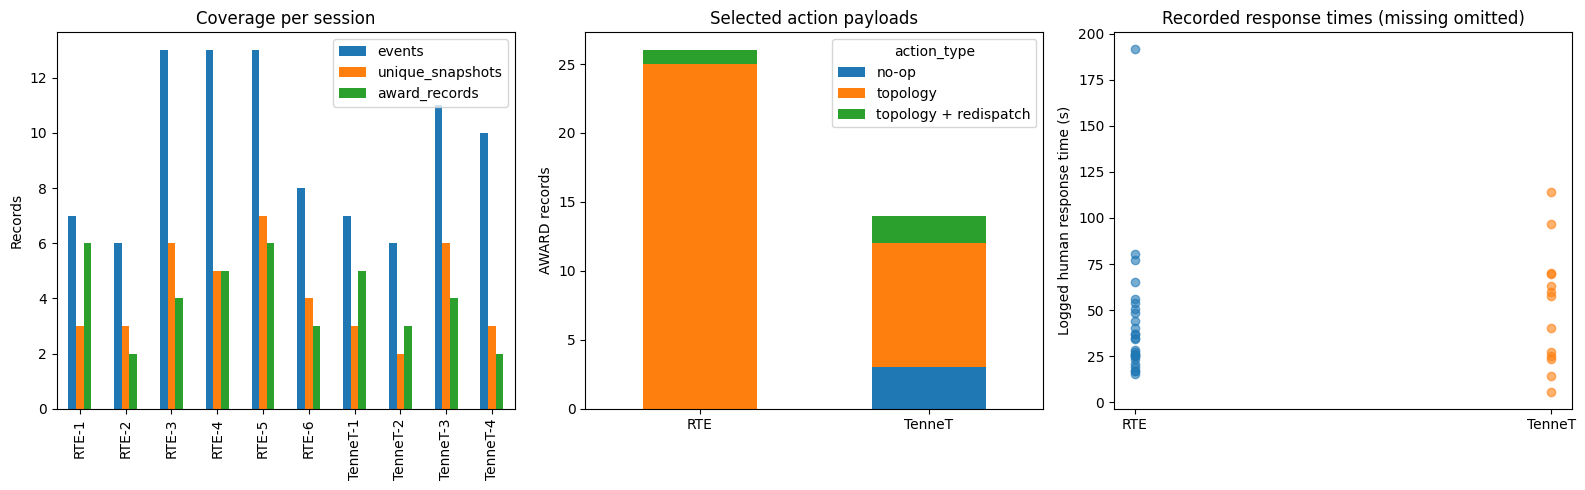

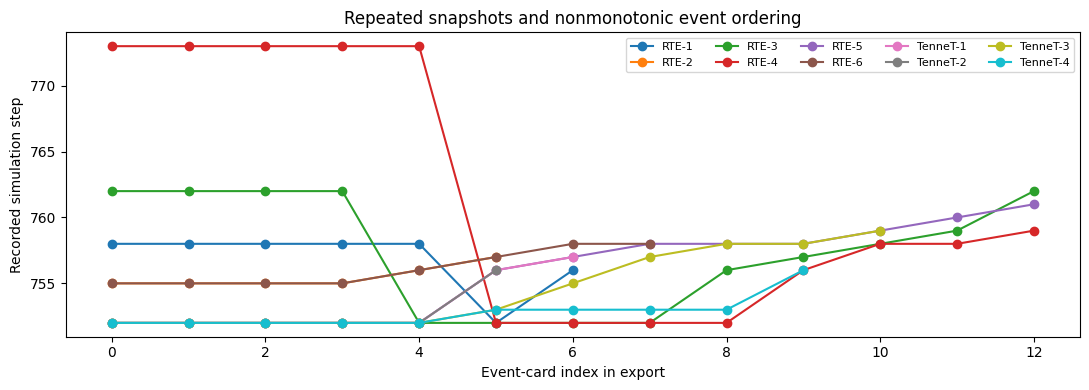

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sessions.set_index("session_label")[["events", "unique_snapshots", "award_records"]].plot.bar(ax=axes[0])
axes[0].set(title="Coverage per session", ylabel="Records", xlabel="")
pd.crosstab(awards.organization, awards.action_type).plot.bar(stacked=True, ax=axes[1], rot=0)
axes[1].set(title="Selected action payloads", ylabel="AWARD records", xlabel="")
for i, org in enumerate(GROUPS):
    values = awards.loc[awards.organization == org, "human_time_s"].dropna()
    axes[2].scatter(np.full(len(values), i), values, alpha=.6)
axes[2].set(xticks=range(2), xticklabels=list(GROUPS), ylabel="Logged human response time (s)", title="Recorded response times (missing omitted)")
save_figure(fig, "coverage_actions_timing")

fig, ax = plt.subplots(figsize=(11, 4))
for sid, group in events.groupby("session_id", sort=False):
    label = sessions.set_index("session_id").loc[sid, "session_label"]
    ax.plot(group.event_id, group.current_step, marker="o", label=label)
ax.set(xlabel="Event-card index in export", ylabel="Recorded simulation step", title="Repeated snapshots and nonmonotonic event ordering")
ax.legend(ncol=5, fontsize=8)
save_figure(fig, "event_state_ordering")

## 6. What this supports for modeling

| Modeling task | Usefulness | What still needs checking |
| :--- | :--- | :--- |
| Observation feature extraction | Good schema compatibility: 59 lines, 22 generators, 37 loads, 177 topology entries | Verify asset identities, deduplicate snapshots, and establish observation time relative to decisions. |
| Human selection among recommendations | Promising: offers, selected title/agent, action vectors, no-op choices | Unchosen candidates have titles rather than full action vectors; timestamp/title matching needs audit. Choice is conditional on the displayed menu. |
| Assistance-use / response-time model | Promising descriptive data: help requests, repeated requests, timing, cognitive context | Small sample, repeated people possible, sparse/possibly updated event context, clock anomalies. |
| Behavioral cloning of grid actions | Candidate demonstrations of human-selected AI actions | AWARD indicates logged selection/application, not confirmed electrical execution. Full contemporaneous state and validity checks are missing. |
| Reward-feature comparison | Current event KPIs and some recommendation predictions are available | `efficiency_of_the_reco` and `predicted_reward` have unspecified semantics here; do not equate them with realized closeToOverflow/economic/distance/AlarmReward. |
| Transition-based inverse RL | Not ready as a complete trajectory dataset | No explicit aligned next-state, realized reward, terminal or legality fields; event adjacency is not a transition. Known rewards are optional for IRL, but credible state/action trajectories or a choice model are still required. |
| Preferences and qualitative interpretation | Surveys and transcripts can suggest objectives and explain choices | Session-level statements are not per-action reward labels; preserve scale definitions and repeated-person structure. |

**Recommended starting dataset:** one row per AWARD, linked to its event card, exact timing summary, previous recommendation list and session survey. Keep the link explicitly named `event_context`, not `state_at_action`. Retain the original vector payloads and recommendation source. A useful first model is operator selection/assistance behavior, conditioned on the offered menu, rather than pooling these logs directly with greedy-agent MDP transitions.

**For stronger grid-policy/IRL modeling:** obtain a stable simulator episode/scenario ID, the exact observation at each decision, full offered action vectors with their predicted metrics, the chosen request and confirmed execution, `s_next`, `done`, legality flags and actual reward components. Confirm whether event cards are updated retrospectively. Deep Expert entries with `context_synced=False` particularly need inspection. Split evaluation by participant/session/scenario, not arbitrary event rows.

RTE Word documents are qualitative context; the session transcript `[AI4REALNET] user study_20261112_1600.docx` describes a fictitious network and simulator. Text extraction here does not verify document layout or transcription accuracy. HTML files are companion reports containing embedded images and should not be counted as extra sessions.

To reuse notebook 01/02's feature functions, map action keys explicitly: `_set_topo_vect → set_bus`, `_change_bus_vect → change_bus`, `_set_line_status → set_line_status`, `_switch_line_status → change_line_status`, `_redispatch → redispatch`, `_curtail → curtail`, `_raise_alarm → raise_alarm`, `_storage_power → storage_power`. Preserve missing sparse components as neutral commands (curtailment neutral is -1). This only normalizes encoding; it does not resolve state/action alignment or execution validity.


The current files contain **16 exact observation snapshots globally** (42 when uniqueness is counted separately within each session). Group identical snapshots/scenarios together during evaluation. This limited state coverage is useful for controlled choice comparisons but insufficient for broad grid-policy generalization. All 38 explicit FEEDBACK entries are confirmations; an unchosen recommendation is not an explicit rejection label. Three AWARD titles do not match the last preceding list within their event card (two are operator-selected no-ops); review the remaining mismatch before making choice pairs.


In [7]:
tables = dict(inventory=inventory, sessions=sessions, events=events, interactions=interactions,
              selected_actions=awards, decision_timings=decisions, offered_titles=offers,
              surveys=surveys, survey_links=survey_link, survey_responses=responses,
              observation_schema=observation_schema, action_schema=action_schema, documents=documents, snapshot_reuse=snapshot_reuse.reset_index())
for name, table in tables.items():
    table.to_csv(OUT / f"{name}.csv", index=False)
summary = sessions.groupby("organization").agg(sessions=("session_id", "size"), events=("events", "sum"),
    unique_snapshots_within_sessions=("unique_snapshots", "sum"), decisions=("award_records", "sum"),
    matched_surveys=("has_survey", "sum"), backward_step_edges=("backward_step_edges", "sum"))
display(summary)
print("Totals:", len(sessions), "sessions;", len(events), "event cards;", len(awards), "selected actions;", len(surveys), "surveys")
print("Action types:", awards.action_type.value_counts().to_dict())
print("All tables and plots saved to", OUT)

Totals: 10 sessions; 94 event cards; 40 selected actions; 8 surveys
Action types: {'topology': 34, 'topology + redispatch': 3, 'no-op': 3}
All tables and plots saved to /Users/dave/Library/CloudStorage/GoogleDrive-davidesalaorni@gmail.com/Il mio Drive/Projects/ai4realnet/greedy-agent/artifacts/participant_audit


,sessions,events,unique_snapshots_within_sessions,decisions,matched_surveys,backward_step_edges
organization,,,,,,
RTE,6,60,28,26,5,3
TenneT,4,34,14,14,3,0
